In [ ]:
%load_ext autoreload
%autoreload 2
%load_ext jupyter_black
import os

os.chdir("/home/slagter/Astronomy_master/STRW-MSC/SF_in_NGC/scripts")
from reproject.mosaicking import find_optimal_celestial_wcs, reproject_and_coadd

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt, matplotlib.gridspec as gridspec
from astropy.io import fits, ascii
from astropy.stats import knuth_bin_width
from astropy.table import Table
from astropy.coordinates import SkyCoord
import phot_toolkit as PTK
import plot_toolkit as PLOT
    import photometric_pipeline as PPL

import astropy.units as u

working_directory = (
    "/net/vdesk/data2/slagter/JWST_NIRCAM_#1227_level_2/mastDownload/JWST"
)
PHOTOMETRIC_pipeline = PPL.Pipeline_level_2_data(working_directory=working_directory)

The autoreload extension is already loaded. To reload it, use:
  %reload_ext autoreload
The jupyter_black extension is already loaded. To reload it, use:
  %reload_ext jupyter_black
Initialized filepaths for :  ['F187N', 'F335M', 'F115W', 'F277W', 'F200W', 'F444W', 'F182M', 'F430M', 'F090W', 'F356W', 'F150W', 'F480M', 'F212N']


In [11]:
catalogue_path = "/home/slagter/Astronomy_master/STRW-MSC/SF_in_NGC/Photometry/catalogue_jeroen/NGC346_NIRCam_and_MIRI_Public_JWST_Catalogue.fits"
Catalogue = PTK.Read_Catalogue(catalogue_path=catalogue_path)

In [17]:
outfile = Catalogue.make_source_list(
    filt_mask_on=("F115W", 2.0),
    outfile="/home/slagter/Astronomy_master/STRW-MSC/SF_in_NGC/Photometry/catalogue_jeroen/positions_F115W.fits",
)

In [18]:
tab_new = Table.read(outfile, hdu=1)

print(tab_new)  # 249519 vs. 201533 with or without mask in F115W

Catalogue_Number        RA              DEC       
                       deg              deg       
---------------- ---------------- ----------------
             CN0       14.7769194      -72.1601907
             CN1       14.7700272      -72.1600488
             CN2       14.7771317      -72.1595729
             CN3       14.7771922      -72.1591325
             CN4       14.7721221      -72.1586775
             CN5       14.7307299      -72.1586006
             CN6       14.7593734      -72.1574489
             CN7       14.7776764      -72.1573902
             CN8       14.7776223      -72.1572986
             ...              ...              ...
        CN201523       14.7318036      -72.1563202
        CN201524       14.7640932      -72.1735656
        CN201525       14.7237670      -72.1721130
        CN201526       14.7618842      -72.1718130
        CN201527       14.7343427      -72.1655759
        CN201528       14.7203451      -72.1603162
        CN201529       14.72582

In [ ]:
filter  = 'F200W'

mask    = (Catalogue.cat_data[1].data[filter] < 50)

samples = Catalogue.cat_data[1].data[filter][mask]
N_samples = len(samples)


fig = plt.figure()
gs = fig.add_gridspec(1, 1, figure=fig, wspace=0, hspace=0)
ax0 = fig.add_subplot(gs[0, 0])

dx, bin_edges = knuth_bin_width(samples, return_bins=True)

print(len(bin_edges))
hist = np.histogram(samples, bins=bin_edges)[0]

ax0.stairs(
    hist,
    edges=bin_edges, fill=False, label=filter, lw=2, edgecolor='black'
    )

ax0.text(
        0.05,
        0.95,
        f'Total = {N_samples}',
        transform=ax0.transAxes,
        fontsize=16,
        verticalalignment="top",
        bbox=dict(boxstyle="round", facecolor="white", alpha=1),
    )
ax0.set_xlabel("Vega Magnitude")
ax0.set_ylabel("Count")
ax0.set_ylim(0, 12500)
fig.suptitle(f"Detected sources in {filter} ")
plt.show()

AttributeError: 'FITS_record' object has no attribute 'data'

In [ ]:
X_color =  Catalogue.cat_data['F115W'] - Catalogue.cat_data['F200W']
Y_color = Catalogue.cat_data['F115W'] - Catalogue.cat_data['F187N']

X_color_acc = X_color[Catalogue.cat_data['Pa-alpha_excess'] == 'Y']
Y_color_acc = Y_color[Catalogue.cat_data['Pa-alpha_excess'] == 'Y']




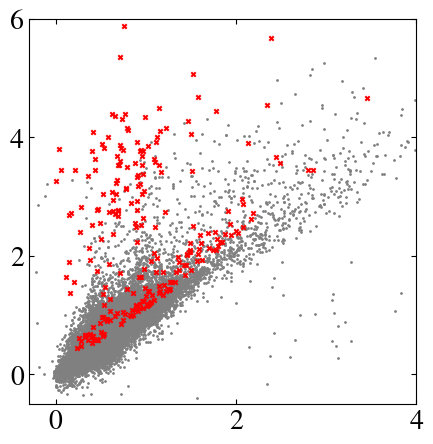

In [ ]:
plt.figure(figsize=(5,5))

plt.scatter( x = X_color,
             y = Y_color,
             c = 'gray', s=1, alpha=1)

plt.scatter( x = X_color_acc,
             y = Y_color_acc,
             c = 'red', s=10, alpha=1, marker='x')


plt.xlim(-0.3, 4)
plt.ylim(-0.5, 6)
plt.xlabel()

plt.show()

In [ ]:


fig = plt.figure()
gs = gridspec.GridSpec(1,1, figure=fig)
ax  = fig.add_subplot(gs[0,0])


X_color
plt.title(f'Color-Color diagram - CMD 3.9 models')
ax.set_xlabel(f'{phot_tk._make_mag_name(filtx1)} - {phot_tk._make_mag_name(filtx2)}')
ax.set_ylabel(f'{_make_mag_name(filty1)} - {phot_tk_make_mag_name(filty2)}')
Fx1_Fx2 = table[filtx1] - table[filtx2] 
Fy1_Fy2 = table[filty1] - table[filty2] 

logAge  = np.min(table['logAge'])
Zini    = np.min(table['Zini'])

Age_colors = {'6.0': '#33BBEE', '8.0' : "#EF8A0E", '10.0': '#EE3377'}
Z_marker   = {str(Zsun): 'o', str(Zsun/5): 'x'}
Z_label    = {str(Zsun): r'$Z_{\odot}$', str(Zsun/5): r'$Z_{\odot}/5$'}
ax.scatter(Fx1_Fx2, Fy1_Fy2, marker=Z_marker[str(Zini)], label=fr'$\log_{{10}} [\mathrm{{t_{{age}}}}]$ = {logAge}, Z =  {Z_label[str(Zini)]}', color = Age_colors[str(logAge)])


ax.set_xlim(xlim)
ax.set_ylim(ylim)

ax.legend()
    
plt.show()

In [ ]:
sort_idx = np.argsort(Y_color)
X_sorted = X_color[sort_idx]
Y_sorted = Y_color[sort_idx]


from scripts.RunningMedian import RunningMedian

WINDOW_SIZE = 1000

w           = RunningMedian(window_size = WINDOW_SIZE )

w.insert(Y_sorted)
plt.plot(X_sorted, w.median())
